# Airline Tweets: Sentiment Analysis Pipeline

This notebook applies the **Naive Bayes** notebook and **Neural Networks Lecture 1** to the two airline files:

- `airline_train_900.csv`: 900 tweets for training (300 negative, 300 neutral, 300 positive)
- `airline_test_60.csv`: 60 tweets for testing (20 of each label)

Each file has two columns: `airline_sentiment` (the label) and `text` (the tweet).

**The pipeline**

1. Load both files
2. Read some of the tweets
3. Pre-process: remove handles and links with `re`, then lowercase and remove stopwords with spaCy
4. Turn the cleaned tweets into word counts (bag of words) with `CountVectorizer`
5. Train Naive Bayes from scratch on the training data only
6. Train the same model with scikit-learn (`Pipeline` + `MultinomialNB`) and check that it matches
7. Predict the 60 test tweets and compare them with the true labels
8. See which words push a tweet toward each label
9. Compare different pre-processing versions
10. Train a small neural network in PyTorch on the same word counts
11. Learn 2-D word embeddings and plot them
12. Summary
13. Try your own tweets

**How to run it on Google Colab**

1. Go to [colab.research.google.com](https://colab.research.google.com), then `File → Upload notebook` and pick this file
2. `Runtime → Run all`
3. When the upload button appears under the "Load the Data" cell, select both CSV files

If you already dragged the two CSV files into Colab's Files panel, the upload step is skipped. Everything runs on the CPU in about a minute.

### Install and Import Libraries

In [1]:
# Colab already has these libraries, this only installs one if it is missing
import importlib.util
import subprocess
import sys

for package, module in [("spacy", "spacy"), ("scikit-learn", "sklearn"), ("pandas", "pandas"),
                        ("torch", "torch"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

In [2]:
import glob
import html
import importlib
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
import torch
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

# Load spaCy's small English model (downloads it first if this runtime does not have it)
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    importlib.invalidate_caches()
    nlp = spacy.load("en_core_web_sm")

# Show long tweets and all 60 test rows in tables
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_rows", 100)

print(f"spaCy {spacy.__version__}, PyTorch {torch.__version__}")

spaCy 3.8.16, PyTorch 2.14.1+cu130


### 1. Load the Data

In [3]:
TRAIN_FILE = "airline_train_900.csv"
TEST_FILE = "airline_test_60.csv"


def find_csv(name):
    # Colab renames a second upload of the same file to "airline_train_900 (1).csv", so also look for copies
    if os.path.exists(name):
        return name
    matches = sorted(glob.glob(f"*{name[:-4]}*.csv"))
    return matches[0] if matches else None


# On Colab, ask for the files if they are not in the Files panel yet
if find_csv(TRAIN_FILE) is None or find_csv(TEST_FILE) is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Put {TRAIN_FILE} and {TEST_FILE} in the same folder as this notebook") from None
    print(f"Select both {TRAIN_FILE} and {TEST_FILE}")
    files.upload()

train_path = find_csv(TRAIN_FILE)
test_path = find_csv(TEST_FILE)
missing = [name for name, path in [(TRAIN_FILE, train_path), (TEST_FILE, test_path)] if path is None]
if missing:
    raise FileNotFoundError(f"Could not find {' and '.join(missing)}. Run this cell again and upload it.")

print(f"Training file: {train_path}")
print(f"Test file:     {test_path}")

Training file: airline_train_900.csv
Test file:     airline_test_60.csv


In [4]:
# Load the train and test splits
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
print(f"Train: {len(train_df)} tweets  {train_df['airline_sentiment'].value_counts().to_dict()}")  # Gets the count of each label
print(f"Test:  {len(test_df)} tweets  {test_df['airline_sentiment'].value_counts().to_dict()}")

Train: 900 tweets  {'negative': 300, 'neutral': 300, 'positive': 300}
Test:  60 tweets  {'negative': 20, 'neutral': 20, 'positive': 20}


### 2. View the Tweets

Read some tweets from each label before doing anything else.

In [5]:
# View three tweets per label, random_state makes it the same tweets every run
for sentiment in ["negative", "neutral", "positive"]:
    for _, row in train_df[train_df["airline_sentiment"] == sentiment].sample(3, random_state=42).iterrows():
        print(f"Label: {row['airline_sentiment']}")
        print(f"Text:  {row['text']}\n")

Label: negative
Text:  @JetBlue supervisor humiliated us and was uncompromising. We were completely blindsided!

Label: negative
Text:  @JetBlue last flight was Cancelled Flightled, then it was 2 hours to change a light bulb, now sitting here waiting for maintenance. Unreal.

Label: negative
Text:  @USAirways - who do I call to use credit fm. prev. cxl tix that can't be rebooked online?Rep I called quoted me $1k higher than the website.

Label: neutral
Text:  @usairways sadly they've tried that and airport agents…no flights so they're stranded at PHL. No chance of a hotel for them?

Label: neutral
Text:  “@JetBlue: Our fleet's on fleek. http://t.co/XX5QSCjlL1” @BrandsSayingBae #Freberg15

Label: neutral
Text:  @united #UnitedAirlines wont wait 10min for fam w 2yr old connecting. flight leaves early instead for airport that is planes last stop today

Label: positive
Text:  @USAirways finally rectified my flight situation! Thanks again

Label: positive
Text:  Thank you @united for your p

Reading the tweets closely shows several things that say nothing about how the person feels:

- **Handles** like `@united` or `@SouthwestAir`. Almost every tweet starts with one.
- **Links** like `http://t.co/abc123`
- **HTML codes**: `&amp;` is `&`, and `&lt;` / `&gt;` are `<` / `>`. Left alone, `CountVectorizer` turns `&amp;` into the word `amp`.
- **A find-and-replace mistake in the original dataset**: every "Cancel" became "Cancelled Flight" and every "Late" became "Late Flight". So "Cancelled" shows up as "Cancelled Flightled" and "Later" as "Late Flightr".
- **Emoji** like 🙏 😭 👍. `CountVectorizer`'s default token pattern only keeps words of 2 or more letters or digits, so emoji are dropped.

In [6]:
# How many training tweets contain each of these?
patterns = {
    "handle like @united": r"@\w+",
    "link like http://t.co/...": r"http\S+",
    "HTML code like &amp;": r"&\w+;",
    "'Cancelled Flight' or 'Late Flight'": r"Cancelled Flight|Late Flight",
}
for name, pattern in patterns.items():
    count = train_df["text"].str.contains(pattern, regex=True).sum()
    print(f"{name:37s} {count:4d} of {len(train_df)} tweets")

handle like @united                    900 of 900 tweets
link like http://t.co/...               87 of 900 tweets
HTML code like &amp;                    35 of 900 tweets
'Cancelled Flight' or 'Late Flight'     62 of 900 tweets


The handle tells us which airline the tweet is about. In this sample the airlines do not have the same mix of labels:

In [7]:
# Labels per airline, using the first handle in each tweet
airline = train_df["text"].str.extract(r"(@\w+)")[0].str.lower().rename("airline")
airline_counts = pd.crosstab(airline, train_df["airline_sentiment"])
airline_counts[airline_counts.sum(axis=1) >= 20]

airline_sentiment,negative,neutral,positive
airline,,,
@americanair,65,45,41
@jetblue,38,72,68
@southwestair,40,58,70
@united,87,72,69
@usairways,66,43,37
@virginamerica,4,9,14


This is the same problem as "Pingo in Antarctica" and "Hale" in the worked example. In pre-processing version 2 of that example, `pingo`, `antarctica` and `hale` became the strongest words pushing toward Negative, only because the film happened to appear in the negative reviews. Here, `jetblue`, `southwestair` and `virginamerica` could push a tweet toward positive, and `usairways` and `americanair` toward negative, just because of each airline's mix of labels in this sample. Removing the handles keeps the model from learning *which airline* instead of *how the person feels*. A few airline names written as hashtags or plain words (`#UnitedAirlines`, "thanks a lot southwest") are left, but they are rare.

### 3. Pre-processing

**Step 1: `re` and string clean-up**

- Turn HTML codes back into characters with `html.unescape` (`&amp;` → `&`)
- Undo the dataset's find-and-replace: "Cancelled Flight" → "Cancel", "Late Flight" → "Late"
- **Handles:** the pattern `r"@\w+"` means "an `@` followed by one or more letters, digits or underscores"
- **Links:** the pattern `r"http\S+"` means "`http` followed by everything up to the next space"
- Remove leading, trailing and double spaces (and line breaks)

In [8]:
def regex_clean(text):
    text = html.unescape(text)                                    # "&amp;" -> "&", "&gt;" -> ">"
    text = text.replace("Cancelled Flight", "Cancel").replace("Late Flight", "Late")  # Undo the dataset's find-and-replace
    text = re.sub(r"@\w+", " ", text)                             # Remove handles like @united
    text = re.sub(r"http\S+", " ", text)                          # Remove links like http://t.co/abc123
    text = " ".join(text.split())                                 # Remove leading, trailing and double spaces
    return text


# Before and after, on the first tweet that has each problem
for pattern in [r"http\S+", r"&\w+;", r"Cancelled Flight", r"Late Flight"]:
    example = train_df["text"][train_df["text"].str.contains(pattern, regex=True)].iloc[0]
    print(f"Before: {example}")
    print(f"After:  {regex_clean(example)}\n")

Before: @AmericanAir now 2 hrs! Guess I should just hang up &amp; give up on using my award miles before prices jump? Hm thanks http://t.co/LE4H2gTzXZ
After:  now 2 hrs! Guess I should just hang up & give up on using my award miles before prices jump? Hm thanks

Before: @USAirways @AmericanAir I love you guys &amp; I'm gonna let you finish, but I've been on hold for 1 hour trying to book a flight w/ my voucher.
After:  I love you guys & I'm gonna let you finish, but I've been on hold for 1 hour trying to book a flight w/ my voucher.

Before: @SouthwestAir flight 1613 Cancelled Flightled??? My wife is stuck in Phoenix on the way from slc to san
Thanks a lot southwest!
After:  flight 1613 Cancelled??? My wife is stuck in Phoenix on the way from slc to san Thanks a lot southwest!

Before: @united hi JH. Yes please. Since I lost almost a whole day on the way out, could you help me change my return for one day Late Flightr?
After:  hi JH. Yes please. Since I lost almost a whole day on the w

**Step 2: spaCy**

Same idea as the worked example: run the tweet through spaCy, lowercase every token and drop the stopwords. Punctuation is dropped too. `CountVectorizer` would ignore it anyway, but the cleaned text is easier to read without it.

There are two switches so we can compare versions later:

- `keep_negations = True` keeps `no`, `not`, `never`, ... even though spaCy lists them as stopwords. "not happy" and "happy" mean opposite things, but once `not` is removed they look the same. spaCy splits "don't" into "do" + "n't", so `n't` is turned into `not`.
- `remove_names = True` also removes words that spaCy tags as a PERSON, like pre-processing version 1 of the worked example

In [9]:
NEGATIONS = {"no", "not", "never", "nor", "none", "nothing", "nobody", "nowhere", "neither", "without"}


def spacy_preprocess(sentence, remove_stopwords=True, keep_negations=False, remove_names=False):
    doc = nlp(sentence)

    tokens = []

    for token in doc:
        if token.is_punct or token.is_space:  # Remove punctuation like "!" and "?"
            continue

        token_to_be_added = token.text.lower()
        if token_to_be_added in ("n't", "n’t"):  # "don't" -> "do" + "n't"
            token_to_be_added = "not"

        if remove_names and token.ent_type_ == "PERSON":  # Remove names, like version 1 of the worked example
            continue
        if remove_stopwords and token.is_stop and not (keep_negations and token_to_be_added in NEGATIONS):
            continue
        tokens.append(token_to_be_added)

    # Join the tokens together
    cleaned_text = " ".join(tokens)

    return cleaned_text


# Show what each step does to a few tweets
for text in train_df["text"].iloc[:4]:
    print(f"Raw:              {text}")
    print(f"After step 1:     {regex_clean(text)}")
    print(f"After step 2:     {spacy_preprocess(regex_clean(text))}")
    print(f"Keeping negation: {spacy_preprocess(regex_clean(text), keep_negations=True)}\n")

Raw:              @united, there is no good word for describing how angry and pissed off of a customer you have made me.
After step 1:     , there is no good word for describing how angry and pissed off of a customer you have made me.
After step 2:     good word describing angry pissed customer
Keeping negation: no good word describing angry pissed customer

Raw:              @united @perfectomobile huh?  I have sent 16 crash reports in Feb alone.  8 in one day.  Only app I have that consistently crashes.
After step 1:     huh? I have sent 16 crash reports in Feb alone. 8 in one day. Only app I have that consistently crashes.
After step 2:     huh sent 16 crash reports feb 8 day app consistently crashes
Keeping negation: huh sent 16 crash reports feb 8 day app consistently crashes

Raw:              @united hi JH. Yes please. Since I lost almost a whole day on the way out, could you help me change my return for one day Late Flightr?
After step 1:     hi JH. Yes please. Since I lost alm

Pre-process every tweet in both files with step 1 and then step 2 (lowercase + remove stopwords). This is the main version used in the rest of the notebook.

In [10]:
# Clean the training and test sets the same way
train_text = [spacy_preprocess(regex_clean(text)) for text in train_df["text"]]
test_text = [spacy_preprocess(regex_clean(text)) for text in test_df["text"]]

train_labels = list(train_df["airline_sentiment"])
test_labels = list(test_df["airline_sentiment"])

print(f"Cleaned Training Set (first 5): {train_text[:5]}\n")
print(f"Cleaned Test Set (first 5):     {test_text[:5]}\n")

# Some tweets are almost all handles and stopwords, e.g. "@AmericanAir followback"
short = [(raw, clean) for raw, clean in zip(train_df["text"], train_text) if len(clean.split()) <= 1]
print(f"{len(short)} training tweets have one word or less left after cleaning, for example:")
for raw, clean in short[:3]:
    print(f"  {raw!r} -> {clean!r}")

Cleaned Training Set (first 5): ['good word describing angry pissed customer', 'huh sent 16 crash reports feb 8 day app consistently crashes', 'hi jh yes lost day way help change return day later', 'flight 1613 cancelled wife stuck phoenix way slc san thanks lot southwest', 'kidding answering calls reserv line high volume option wait brutal']

Cleaned Test Set (first 5):     ['departure people delayed $ 200 compensate time', 'yes newly married trying update preexisting international flight easy', 'mention silver preferred member fly week meal voucher', 'earnings low checkin people tarmac loading bags jan', 'customer service joke mechanical cancelation weather hold 5:30 humans pls']

62 training tweets have one word or less left after cleaning, for example:
  "@AmericanAir you're almost as bad as @united" -> 'bad'
  '@SouthwestAir prove it' -> 'prove'
  '@USAirways I already HAVE, four times' -> 'times'


### 4. Text Representation: Bag of Words

- Use `CountVectorizer` for the bag of words
- Fit it on the **training data** only, then use the same vocabulary for the test data. Test words that are not in the training vocabulary are ignored.

In [11]:
# Create the CountVectorizer (this builds the BoW model)
# binary = False counts the number of times a token appears in a tweet
vectorizer = CountVectorizer(binary=False)

# Fit and transform the training tweets into a BoW matrix, then transform the test tweets with the same vocabulary
bow_train = vectorizer.fit_transform(train_text)
bow_test = vectorizer.transform(test_text)

vocab = vectorizer.get_feature_names_out()
print(f"Training BoW matrix: {bow_train.shape[0]} tweets x {bow_train.shape[1]} words")
print(f"Test BoW matrix:     {bow_test.shape[0]} tweets x {bow_test.shape[1]} words\n")

# The 20 most frequent words in the training tweets
word_counts = np.asarray(bow_train.sum(axis=0)).ravel()
most_common = word_counts.argsort()[::-1][:20]
print(f"Most frequent words: {[(vocab[i], int(word_counts[i])) for i in most_common]}\n")

# One tweet as a bag of words (only the words that appear, the other entries are 0)
print(f"Training Tweet 1 ({train_labels[0]}): {train_text[0]}")
row = bow_train[0]
print(f"BOW Representation 1 (non-zero entries): {dict(zip(vocab[row.indices], row.data.tolist()))}")

Training BoW matrix: 900 tweets x 2380 words
Test BoW matrix:     60 tweets x 2380 words

Most frequent words: [('flight', 178), ('thanks', 100), ('thank', 70), ('service', 55), ('help', 44), ('customer', 43), ('time', 40), ('great', 35), ('got', 33), ('flights', 33), ('gate', 31), ('flying', 30), ('need', 30), ('hours', 30), ('plane', 29), ('today', 29), ('like', 27), ('airport', 26), ('good', 26), ('hold', 26)]

Training Tweet 1 (negative): good word describing angry pissed customer
BOW Representation 1 (non-zero entries): {'good': 1, 'word': 1, 'describing': 1, 'angry': 1, 'pissed': 1, 'customer': 1}


In [12]:
# How many test words are not in the training vocabulary?
analyzer = vectorizer.build_analyzer()
test_words = [w for doc in test_text for w in analyzer(doc)]
unknown = [w for w in test_words if w not in vectorizer.vocabulary_]
print(f"{len(unknown)} of {len(test_words)} test words are not in the training vocabulary and are skipped")
print(f"Examples: {sorted(set(unknown))[:15]}")

91 of 426 test words are not in the training vocabulary and are skipped
Examples: ['05', '1712', '200', '769', '85832', 'adopted', 'al', 'arrangements', 'asap', 'automatically', 'avon', 'back', 'calling', 'cellphone', 'channel']


### 5. Naive Bayes from Scratch

The same functions as the worked example. The only difference is that there are now three classes $C$ = {negative, neutral, positive}.

The predicted class $\hat{c}$ is the class with the highest log prior plus the sum of the log likelihoods of the words in the test document:

$$
\hat{c} = \underset{c \in C}{\operatorname{argmax}} \; \Big[ \log P(c) + \sum_{i=1}^{n} \log P(w_i \mid c) \Big]
$$

where $w_1, \dots, w_n$ are the words of the test tweet that appear in the training vocabulary $V$ (the unknown test words counted in section 4 are skipped).

**Prior**: the fraction of training documents that belong to class $c$

$$
P(c) = \frac{N_c}{N_{doc}}
$$

**Likelihood**: how often word $w_i$ appears in class $c$, relative to all words in class $c$, using Laplace (add-one) smoothing

$$
P(w_i \mid c) = \frac{\mathrm{count}(w_i, c) + 1}{\sum_{w \in V} \mathrm{count}(w, c) + |V|}
$$

In [13]:
# This is how the vectorizer further pre-processes the already pre-processed text
# Keep this so the scratch version uses the same tokens as CountVectorizer
tokenize = vectorizer.build_analyzer()


def train_naive_bayes(D, labels):
    '''
    D = documents or the training data (must be pre-processed based on our manual pre-processing)
    labels - class labels
    '''
    # Gets the unique classes
    C = sorted(set(labels))

    # log_prior[c] = log P(c)
    log_prior = {}

    # log_likelihood[(w, c)] = log P(w | c)
    log_likelihood = {}

    # Calculate P(c) terms
    N_doc = len(D)

    # V: vocabulary of D
    V = set()
    for d in D:
        V.update(tokenize(d))
    V = sorted(V)

    # Loop through all classes
    for c in C:

        # Count how many documents belong to each class and calculate the log prior of each class
        N_c = sum(1 for label in labels if label == c)
        log_prior[c] = np.log(N_c / N_doc)

        # bigdoc is the collection of documents that belong to class c
        bigdoc = []
        for d, label in zip(D, labels):
            if label == c:
                bigdoc.extend(tokenize(d))

        # Counts the number of times each word in class c occurs
        counts = Counter(bigdoc)

        # Denominator with Laplace smoothing
        denom = sum(counts[w] for w in V) + len(V)

        # Calculate P(w|c) terms
        for w in V:
            log_likelihood[(w, c)] = np.log((counts[w] + 1) / denom)  # with Laplace smoothing

    return log_prior, log_likelihood, V, C


def test_naive_bayes(testdoc, log_prior, log_likelihood, C, V):
    V = set(V)
    total = {}

    # Calculate the score for each class
    for c in C:
        total[c] = log_prior[c]
        for word in tokenize(testdoc):          # Tokenizes the test data the same way as the training data
            if word in V:                       # Unknown words are skipped
                total[c] += log_likelihood[(word, c)]
    return max(total, key=total.get), total     # argmax of the resulting sums

In [14]:
# Perform the training step on our training data
log_prior, log_likelihood, V, C = train_naive_bayes(train_text, train_labels)

print(f"Classes: {C}")
print(f"Log Prior: { {c: round(float(p), 4) for c, p in log_prior.items()} }")  # 300 of 900 tweets each, so log(1/3) = -1.0986
print(f"Vocabulary size: {len(V)}\n")

# A few log likelihoods
for w in ["thanks", "great", "delayed", "hold", "flight"]:
    print(f"{w:8s} " + "   ".join(f"log P({w} | {c}) = {log_likelihood[(w, c)]:.3f}" for c in C))

Classes: ['negative', 'neutral', 'positive']
Log Prior: {'negative': -1.0986, 'neutral': -1.0986, 'positive': -1.0986}
Vocabulary size: 2380

thanks   log P(thanks | negative) = -5.921   log P(thanks | neutral) = -5.419   log P(thanks | positive) = -4.076
great    log P(great | negative) = -6.876   log P(great | neutral) = -6.977   log P(great | positive) = -4.971
delayed  log P(delayed | negative) = -5.713   log P(delayed | neutral) = -7.670   log P(delayed | positive) = -7.646
hold     log P(hold | negative) = -5.267   log P(hold | neutral) = -7.670   log P(hold | positive) = -7.646
flight   log P(flight | negative) = -4.103   log P(flight | neutral) = -4.320   log P(flight | positive) = -4.555


In [15]:
# Predict every test tweet
scratch_predictions = []
for doc in test_text:
    argmax, total = test_naive_bayes(doc, log_prior, log_likelihood, C, V)
    scratch_predictions.append(argmax)

print(f"Scratch Naive Bayes test accuracy: {accuracy_score(test_labels, scratch_predictions):.4f}\n")

# One test tweet in detail
argmax, total = test_naive_bayes(test_text[0], log_prior, log_likelihood, C, V)
print(f"Test Tweet:         {test_df['text'][0]}")
print(f"Cleaned Test Tweet: {test_text[0]}")
print(f"True Class:         {test_labels[0]}")
print(f"Predicted Class:    {argmax}")
print(f"Total: { {c: round(float(t), 3) for c, t in total.items()} }")

Scratch Naive Bayes test accuracy: 0.6000

Test Tweet:         @JetBlue before departure, while people who are delayed get up to $200 to compensate their time..
Cleaned Test Tweet: departure people delayed $ 200 compensate time
True Class:         negative
Predicted Class:    negative
Total: {'negative': -27.837, 'neutral': -29.764, 'positive': -28.685}


### 6. Wrap it all up in scikit-learn

In [16]:
# CountVectorizer and then Naive Bayes
# Input must be the pre-processed training data or test data
model = Pipeline([
    ("bow", CountVectorizer(binary=False)),  # Same settings as above
    ("nb", MultinomialNB(alpha=1)),          # alpha = 1 is Laplace smoothing
])

# Trains the Naive Bayes model on the cleaned training data
model.fit(train_text, train_labels)

print(f"Train accuracy: {model.score(train_text, train_labels):.4f}")
print(f"Test accuracy:  {model.score(test_text, test_labels):.4f}")

Train accuracy: 0.9333
Test accuracy:  0.6000


In [17]:
# Check that scikit-learn learned the same numbers as the scratch version
nb = model.named_steps["nb"]
sk_vocab = model.named_steps["bow"].get_feature_names_out()

prior_diff = max(abs(nb.class_log_prior_[i] - log_prior[c]) for i, c in enumerate(nb.classes_))
likelihood_diff = max(abs(nb.feature_log_prob_[i, j] - log_likelihood[(w, c)])
                      for i, c in enumerate(nb.classes_) for j, w in enumerate(sk_vocab))

sklearn_predictions = model.predict(test_text)
agree = sum(a == b for a, b in zip(scratch_predictions, sklearn_predictions))

print(f"Same vocabulary:                  {list(sk_vocab) == V}")
print(f"Largest difference in log P(c):   {prior_diff:.1e}")
print(f"Largest difference in log P(w|c): {likelihood_diff:.1e}")
print(f"Same prediction on {agree} of {len(test_text)} test tweets")

Same vocabulary:                  True
Largest difference in log P(c):   2.2e-16
Largest difference in log P(w|c): 8.9e-16
Same prediction on 60 of 60 test tweets


In [18]:
# Probability of each class (normalized via softmax) for the first 5 test tweets
proba = model.predict_proba(test_text)
pd.DataFrame(proba[:5].round(3), columns=nb.classes_).assign(predicted=sklearn_predictions[:5], true=test_labels[:5],
                                                             tweet=test_df["text"][:5])

,negative,neutral,positive,predicted,true,tweet
0,0.635,0.093,0.272,negative,negative,"@JetBlue before departure, while people who are delayed get up to $200 to compensate their time.."
1,0.310,0.415,0.275,neutral,negative,"@united yes please! I am newly married and trying to update my last name on a preexisting international flight! It seems so easy, but..."
2,0.759,0.075,0.166,negative,negative,"@USAirways @AmericanAir did I mention I'm a silver preferred member and fly every week (not always with you), and not even a meal voucher?"
3,0.879,0.018,0.103,negative,negative,@united Are your earnings so low that checkin people have to also be on Tarmac loading bags? JAN
4,0.996,0.000,0.004,negative,negative,"@USAirways your customer service is a joke. First a mechanical Cancelled Flightation, now weather. On hold since 5:30 am. No humans. Pls..."


### 7. Evaluate on the Test Set

Compare the predicted labels of the 60 test tweets with the true labels.

- **Precision**: of the tweets predicted as this label, how many really are
- **Recall**: of the tweets that really are this label, how many were found
- With only 60 test tweets, one tweet is worth 1.7 percentage points of accuracy

Test accuracy: 0.6000  (36 of 60 correct)

              precision    recall  f1-score   support

    negative      0.552     0.800     0.653        20
     neutral      0.545     0.300     0.387        20
    positive      0.700     0.700     0.700        20

    accuracy                          0.600        60
   macro avg      0.599     0.600     0.580        60
weighted avg      0.599     0.600     0.580        60



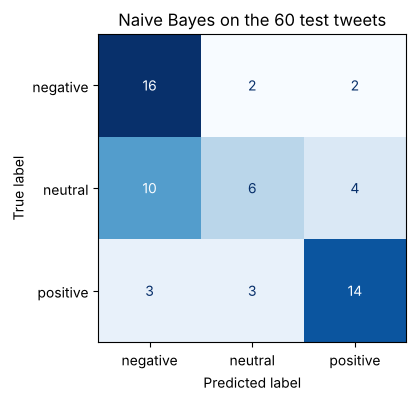

In [19]:
correct = sum(t == p for t, p in zip(test_labels, sklearn_predictions))
print(f"Test accuracy: {accuracy_score(test_labels, sklearn_predictions):.4f}  ({correct} of {len(test_labels)} correct)\n")
print(classification_report(test_labels, sklearn_predictions, digits=3))

# Rows are the true labels, columns are the predicted labels
cm = confusion_matrix(test_labels, sklearn_predictions, labels=nb.classes_)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=nb.classes_).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Naive Bayes on the 60 test tweets")
plt.show()

In [20]:
# Every test tweet with its true and predicted label
results = pd.DataFrame({
    "tweet": test_df["text"],
    "true": test_labels,
    "predicted": sklearn_predictions,
    "P(predicted)": proba.max(axis=1).round(3),
})
results["correct"] = results["true"] == results["predicted"]
results

,tweet,true,predicted,P(predicted),correct
0,"@JetBlue before departure, while people who are delayed get up to $200 to compensate their time..",negative,negative,0.635,True
1,"@united yes please! I am newly married and trying to update my last name on a preexisting international flight! It seems so easy, but...",negative,neutral,0.415,False
2,"@USAirways @AmericanAir did I mention I'm a silver preferred member and fly every week (not always with you), and not even a meal voucher?",negative,negative,0.759,True
3,@united Are your earnings so low that checkin people have to also be on Tarmac loading bags? JAN,negative,negative,0.879,True
4,"@USAirways your customer service is a joke. First a mechanical Cancelled Flightation, now weather. On hold since 5:30 am. No humans. Pls...",negative,negative,0.996,True
5,@AmericanAir can someone actually either call back or help me figure out how I'm getting home??!,negative,neutral,0.574,False
6,@united -How is it that all my flight times were changed without any official notification? Almost missed my flight this morning. Not cool!,negative,negative,0.961,True
7,"@united Would be nice if @staralliance partner tickets that don't provide full PQM credit are more obvious before purchase. Lost 1,200 m...",negative,negative,0.747,True
8,@SouthwestAir please PM me the number where I can lodge formal complaints. Thx,negative,positive,0.654,False
9,@USAirways @jhughes1025 grrrrrrrr. Couldn't book a flight via calling either :(,negative,negative,0.461,True


In [21]:
# The tweets it got wrong, with the cleaned text the model actually saw
wrong = results[~results["correct"]].copy()
wrong["cleaned"] = [test_text[i] for i in wrong.index]
wrong[["tweet", "cleaned", "true", "predicted", "P(predicted)"]]

,tweet,cleaned,true,predicted,P(predicted)
1,"@united yes please! I am newly married and trying to update my last name on a preexisting international flight! It seems so easy, but...",yes newly married trying update preexisting international flight easy,negative,neutral,0.415
5,@AmericanAir can someone actually either call back or help me figure out how I'm getting home??!,actually help figure getting home,negative,neutral,0.574
8,@SouthwestAir please PM me the number where I can lodge formal complaints. Thx,pm number lodge formal complaints thx,negative,positive,0.654
13,@JetBlue Only middle seats. SFO -&gt; BOS. Not fun. She keeps getting $10 credits. Would much rather have a working TV.,middle seats sfo > bos fun keeps getting $ 10 credits working tv,negative,positive,0.902
21,"@USAirways got transf. to Dividend Miles...need to change flight. Grandma just passed, need to change ticket ASAP. Update on wait time?",got transf dividend miles need change flight grandma passed need change ticket asap update wait time,neutral,negative,0.503
24,"@USAirways Do your flight schedules to - from Quintana Roo, Mexico reflect their newly adopted time zone change to EST?",flight schedules quintana roo mexico reflect newly adopted time zone change est,neutral,negative,0.595
25,@USAirways how do you have only 1 flight into lexington this afternoon with the #1 @KentuckyMBB playing a big game tonight? #DoBetter,1 flight lexington afternoon 1 playing big game tonight dobetter,neutral,positive,0.424
26,"@VirginAmerica Is flight 769 on it's way? Was supposed to take off 30 minutes ago. Website still shows ""On Time"" not ""In Flight"". Thanks.",flight 769 way supposed 30 minutes ago website shows time flight thanks,neutral,negative,0.870
28,@united I'm a UA 1k. I think it's @iamtedking who was looking for help,ua 1k think looking help,neutral,negative,0.637
29,@USAirways How do I get a receipt for a change fee when I originally booked with miles?,receipt change fee originally booked miles,neutral,negative,0.654


**What goes wrong?**

- Neutral is the hardest label (lowest recall). Many neutral tweets are questions about flights, changes and fees, and the same words show up in complaints, so they get pulled toward negative.
- Short tweets have very few words left after cleaning. If none of them is in the training vocabulary (like "@AmericanAir followback"), all three classes keep their equal prior, every probability is 0.333, and the tie goes to the first class, negative. If one known word is left, that word decides the label.
- Some tweets are hard even for a person, like a polite complaint that ends with "Thx".

### 8. Which Words Push Toward Each Label?

Same idea as the log-likelihood ratio in the worked example: $\log P(w \mid pos) - \log P(w \mid neg)$. Above 0 pushes toward positive, below 0 toward negative.

In [22]:
# Row index of each class in feature_log_prob_
pos = list(nb.classes_).index("positive")
neg = list(nb.classes_).index("negative")
neu = list(nb.classes_).index("neutral")

word_scores = pd.DataFrame({
    "word": sk_vocab,
    "count": np.asarray(model.named_steps["bow"].transform(train_text).sum(axis=0)).ravel(),
    "log P(w|pos)": nb.feature_log_prob_[pos],
    "log P(w|neg)": nb.feature_log_prob_[neg],
})

# Log-likelihood ratio is log (P(w | pos) / P(w | neg)), which the log turns into a difference
word_scores["LLR (pos - neg)"] = word_scores["log P(w|pos)"] - word_scores["log P(w|neg)"]

# Sort scores by most impact towards a sentiment
word_scores = word_scores.sort_values("LLR (pos - neg)", ascending=False)

print("Words pushing toward 'positive':")
print(word_scores.head(10).round(3).to_string(index=False))
print("\nWords pushing toward 'negative':")
print(word_scores.tail(10).iloc[::-1].round(3).to_string(index=False))  # [::-1] shows the most negative first

Words pushing toward 'positive':
   word  count  log P(w|pos)  log P(w|neg)  LLR (pos - neg)
amazing     11        -5.854        -8.485            2.632
  thank     70        -4.278        -6.876            2.598
    thx      7        -6.259        -8.485            2.226
   best     16        -5.774        -7.792            2.019
    den      6        -6.547        -8.485            1.938
  quick      5        -6.547        -8.485            1.938
  great     35        -4.971        -6.876            1.905
 thanks    100        -4.076        -5.921            1.844
  makes      4        -6.729        -8.485            1.756
   mint      5        -6.729        -8.485            1.756

Words pushing toward 'negative':
     word  count  log P(w|pos)  log P(w|neg)  LLR (pos - neg)
cancelled     16        -8.339        -5.921           -2.418
     hold     26        -7.646        -5.267           -2.379
     line     10        -8.339        -6.088           -2.251
    hours     30        -

With three labels, we can also ask for each label: how much more likely is the word under this label than under the next most likely label? $\log P(w \mid c) - \max_{c' \neq c} \log P(w \mid c')$. Above 0 means the word favours $c$ over both other labels.

Only words that appear at least 5 times are listed. With add-one smoothing, a word seen 3 or 4 times in one label and never in the others gets a large score by chance.

In [23]:
# Words that favour each label over both other labels
class_margin = {}
for i, c in enumerate(nb.classes_):
    others = np.delete(nb.feature_log_prob_, i, axis=0).max(axis=0)  # The larger of the other two log likelihoods
    class_margin[c] = nb.feature_log_prob_[i] - others
    top = [j for j in class_margin[c].argsort()[::-1] if word_counts[j] >= 5][:12]  # Skip words seen fewer than 5 times
    print(f"{c:9s} " + ", ".join(f"{sk_vocab[j]} ({class_margin[c][j]:.2f})" for j in top))

negative  hold (2.38), line (2.25), hours (2.12), bags (1.99), delayed (1.93), system (1.80), waiting (1.73), hour (1.59), let (1.36), miss (1.24), canceled (1.24), late (1.15)
neutral   question (2.17), fleek (1.59), fleet (1.59), aa (1.33), dfw (1.23), rt (1.23), ok (1.23), left (1.22), tomorrow (1.22), nt (1.07), plus (1.07), nashville (1.07)
positive  amazing (2.51), thx (2.10), great (1.90), quick (1.82), thank (1.78), awesome (1.40), thanks (1.34), safely (1.25), best (1.20), happy (1.12), enjoy (1.12), den (1.12)


### 9. Compare Pre-processing Versions

Like versions 1 and 2 of the worked example, try different pre-processing and see what changes. Each version goes through the same `CountVectorizer` + `MultinomialNB` pipeline.

| Version | Pre-processing |
|---|---|
| A | none, raw tweets (`CountVectorizer` still lowercases) |
| B | step 1 only (`re` clean-up) |
| C | step 1 + spaCy lowercase and stopword removal **(main version above)** |
| D | C, but keep negations (`not`, `no`, `never`, ...) |
| E | C, and also remove PERSON names |

The test set has only 60 tweets, so a difference of one or two tweets between versions can be luck. **5-fold cross-validation** on the training set gives a steadier comparison: split the 900 training tweets into 5 parts, train on 4 and test on the 5th, 5 times, and average. The test set is not used for it.

In [24]:
versions = {
    "A. raw tweets": lambda text: text,
    "B. step 1 only": regex_clean,
    "C. step 1 + spaCy (main)": lambda text: spacy_preprocess(regex_clean(text)),
    "D. C + keep negations": lambda text: spacy_preprocess(regex_clean(text), keep_negations=True),
    "E. C + remove names": lambda text: spacy_preprocess(regex_clean(text), remove_names=True),
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
version_models = {}
cv_by_version = {}
rows = []
for name, preprocess in versions.items():
    version_train = [preprocess(text) for text in train_df["text"]]
    version_test = [preprocess(text) for text in test_df["text"]]

    version_model = Pipeline([("bow", CountVectorizer(binary=False)), ("nb", MultinomialNB(alpha=1))])
    cv_scores = cross_val_score(version_model, version_train, train_labels, cv=folds)
    cv_by_version[name] = cv_scores
    version_model.fit(version_train, train_labels)
    version_predictions = version_model.predict(version_test)
    version_models[name] = version_model

    rows.append({
        "version": name,
        "vocabulary size": len(version_model.named_steps["bow"].vocabulary_),
        "5-fold CV accuracy": f"{cv_scores.mean():.3f} ± {cv_scores.std():.3f}",
        "test accuracy": round(accuracy_score(test_labels, version_predictions), 3),
        "test correct (of 60)": sum(t == p for t, p in zip(test_labels, version_predictions)),
    })

pd.DataFrame(rows)

,version,vocabulary size,5-fold CV accuracy,test accuracy,test correct (of 60)
0,A. raw tweets,2798,0.647 ± 0.020,0.583,35
1,B. step 1 only,2617,0.621 ± 0.009,0.667,40
2,C. step 1 + spaCy (main),2380,0.601 ± 0.023,0.600,36
3,D. C + keep negations,2388,0.618 ± 0.024,0.617,37
4,E. C + remove names,2293,0.598 ± 0.026,0.617,37


The ± is how much the score moves from fold to fold. Every version is scored on the same 5 folds, so a fairer way to compare two versions is fold by fold:

In [25]:
# Every version is scored on the same 5 folds, so compare them fold by fold
pairs = [("B. step 1 only", "C. step 1 + spaCy (main)"),
         ("D. C + keep negations", "C. step 1 + spaCy (main)"),
         ("A. raw tweets", "B. step 1 only")]
for a, b in pairs:
    diff = cv_by_version[a] - cv_by_version[b]
    print(f"{a[0]} minus {b[0]} on each fold: {diff.round(3)}  mean {diff.mean():+.3f}, {a[0]} higher on {(diff > 0).sum()} of 5 folds")

B minus C on each fold: [ 0.     0.056 -0.006  0.011  0.039]  mean +0.020, B higher on 3 of 5 folds
D minus C on each fold: [0.017 0.011 0.022 0.011 0.022]  mean +0.017, D higher on 5 of 5 folds
A minus B on each fold: [0.017 0.011 0.056 0.028 0.017]  mean +0.026, A higher on 5 of 5 folds


**Reading the results**

- Removing stopwords (C) does not help on this data: B keeps them and scores higher on average. spaCy's stopword list was made for general text, and it includes words like `not`, `no`, `nothing`, `still`, `why`, `if` and `can` that lean toward a label in these tweets (next cell).
- Keeping the negations (D) beats C on every fold, so that part of the stopword list is worth keeping.
- The raw tweets (A) also keep the handles. Part of their higher score comes from learning the airline (last cell of this section). That works on this sample, but it is not sentiment.
- The test column ranks the versions differently (A is best in cross-validation but worst on the test set). 60 test tweets are too few to rank versions, which is why the comparison uses cross-validation.

In [26]:
# Stopwords that lean toward a label, from version B (which keeps them)
# Only stopwords seen at least 8 times in training, so very rare words do not crowd the list
b_model = version_models["B. step 1 only"]
b_nb = b_model.named_steps["nb"]
b_vocab = b_model.named_steps["bow"].get_feature_names_out()
b_counts = np.asarray(b_model.named_steps["bow"].transform([regex_clean(t) for t in train_df["text"]]).sum(axis=0)).ravel()

for i, c in enumerate(b_nb.classes_):
    margin = b_nb.feature_log_prob_[i] - np.delete(b_nb.feature_log_prob_, i, axis=0).max(axis=0)
    leaning = [(b_vocab[j], round(float(margin[j]), 2)) for j in margin.argsort()[::-1]
               if b_vocab[j] in nlp.Defaults.stop_words and b_counts[j] >= 8 and margin[j] > 0]
    print(f"{c:9s} {leaning[:12]}")

negative  [('should', 1.49), ('because', 1.42), ('not', 1.29), ('still', 1.25), ('nothing', 1.2), ('without', 1.2), ('no', 1.08), ('than', 1.07), ('after', 1.06), ('why', 0.92), ('never', 0.87), ('over', 0.87)]
neutral   [('if', 0.78), ('last', 0.74), ('when', 0.72), ('can', 0.69), ('name', 0.65), ('via', 0.65), ('do', 0.59), ('our', 0.54), ('am', 0.53), ('please', 0.51), ('out', 0.5), ('what', 0.46)]
positive  [('much', 1.62), ('always', 0.82), ('by', 0.65), ('well', 0.64), ('very', 0.64), ('even', 0.57), ('she', 0.55), ('again', 0.52), ('take', 0.51), ('you', 0.48), ('made', 0.47), ('down', 0.46)]


Without pre-processing (version A), the airline handles become features, like `pingo`, `antarctica` and `hale` did in the worked example:

In [27]:
# Where do the airline names rank in version A?
raw_model = version_models["A. raw tweets"]
raw_nb = raw_model.named_steps["nb"]
raw_vocab = list(raw_model.named_steps["bow"].get_feature_names_out())
raw_llr = raw_nb.feature_log_prob_[pos] - raw_nb.feature_log_prob_[neg]
order = list(np.argsort(raw_llr))  # From most negative to most positive

for handle in ["usairways", "americanair", "united", "southwestair", "jetblue", "virginamerica"]:
    j = raw_vocab.index(handle)
    print(f"{handle:14s} LLR (pos - neg) = {raw_llr[j]:+.3f}   rank {order.index(j) + 1} of {len(raw_vocab)} (1 = most negative)")

usairways      LLR (pos - neg) = -0.370   rank 1036 of 2798 (1 = most negative)
americanair    LLR (pos - neg) = -0.200   rank 1069 of 2798 (1 = most negative)
united         LLR (pos - neg) = -0.003   rank 1165 of 2798 (1 = most negative)
southwestair   LLR (pos - neg) = +0.755   rank 2078 of 2798 (1 = most negative)
jetblue        LLR (pos - neg) = +0.719   rank 2072 of 2798 (1 = most negative)
virginamerica  LLR (pos - neg) = +1.311   rank 2706 of 2798 (1 = most negative)


### 10. Neural Network on the Bag of Words (PyTorch)

Same inputs as Naive Bayes (the word counts of the main version), but now a network learns the weights:

- **Input**: the bag-of-words vector of a tweet, one number per vocabulary word
- **Hidden layer**: `Linear` + `ReLU` (32 neurons)
- **Output layer**: `Linear` with 3 outputs, one score (logit) per label
- **Loss**: the XOR example had one output, so it used `Sigmoid` + binary cross-entropy. With three labels we use **softmax** + cross-entropy. `torch.nn.CrossEntropyLoss` applies the softmax itself, so the network has no softmax layer.
- **Training loop**: the same four steps as the lecture: forward pass, loss, backward pass (`loss.backward()`), optimizer step (Adam)

A network can keep improving on the training tweets long after it stops improving on new tweets (overfitting). To make every choice **without looking at the test set**, hold out 20% of the training tweets as a **validation set**:

1. Train on the other 80% and pick the step with the lowest validation loss
2. Try the lecture's experiments (learning rate, activation, hidden size) on the validation set
3. Retrain on all 900 training tweets for that many steps, then evaluate on the test set once

In [28]:
# Labels as numbers: negative = 0, neutral = 1, positive = 2
CLASSES = list(nb.classes_)
label_to_id = {c: i for i, c in enumerate(CLASSES)}
y_train_all = np.array([label_to_id[c] for c in train_labels])
y_test = torch.tensor([label_to_id[c] for c in test_labels])

# Hold out 20% of the training tweets (60 of each label) as a validation set
sub_text, val_text, sub_y, val_y = train_test_split(train_text, y_train_all, test_size=0.2,
                                                    stratify=y_train_all, random_state=42)
y_sub = torch.tensor(sub_y)
y_val = torch.tensor(val_y)


def to_tensor(bow):
    # Sparse BoW matrix -> dense float tensor
    return torch.tensor(bow.toarray(), dtype=torch.float32)


# Vocabulary from the 720 sub-training tweets only, the validation tweets play the role of new data
nn_vectorizer = CountVectorizer(binary=False)
X_sub = to_tensor(nn_vectorizer.fit_transform(sub_text))
X_val = to_tensor(nn_vectorizer.transform(val_text))
print(f"Sub-training: {X_sub.shape[0]} tweets x {X_sub.shape[1]} words,  validation: {X_val.shape[0]} tweets")

Sub-training: 720 tweets x 2039 words,  validation: 180 tweets


In [29]:
def make_network(vocab_size, hidden_size=32, activation=torch.nn.ReLU):
    return torch.nn.Sequential(
        torch.nn.Linear(vocab_size, hidden_size),   # Hidden layer
        activation(),
        torch.nn.Linear(hidden_size, len(CLASSES)),  # Output layer: one score per label, softmax is in the loss
    )


def accuracy(scores, y):
    return (scores.argmax(dim=1) == y).float().mean().item()


def train_network(net, X, y, X_val=None, y_val=None, lr=0.01, epochs=100, optimizer=torch.optim.Adam, weight_decay=0.0):
    # Full-batch training loop from the lecture: every step uses all training tweets
    opt = optimizer(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = torch.nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for step in range(epochs):
        scores = net(X)                 # Forward pass
        loss = loss_fn(scores, y)       # Loss
        opt.zero_grad()                 # Gradients accumulate, so zero them first
        loss.backward()                 # Backward pass
        opt.step()                      # Update the weights

        history["train_loss"].append(loss.item())
        history["train_acc"].append(accuracy(scores, y))
        if X_val is not None:
            with torch.no_grad():
                val_scores = net(X_val)
            history["val_loss"].append(loss_fn(val_scores, y_val).item())
            history["val_acc"].append(accuracy(val_scores, y_val))
    return history


def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
    ax1.plot(history["train_loss"], label="train")
    ax1.plot(history["val_loss"], label="validation")
    ax1.set_xlabel("step")
    ax1.set_ylabel("cross-entropy loss")
    ax1.legend()
    ax2.plot(history["train_acc"], label="train")
    ax2.plot(history["val_acc"], label="validation")
    ax2.set_xlabel("step")
    ax2.set_ylabel("accuracy")
    ax2.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

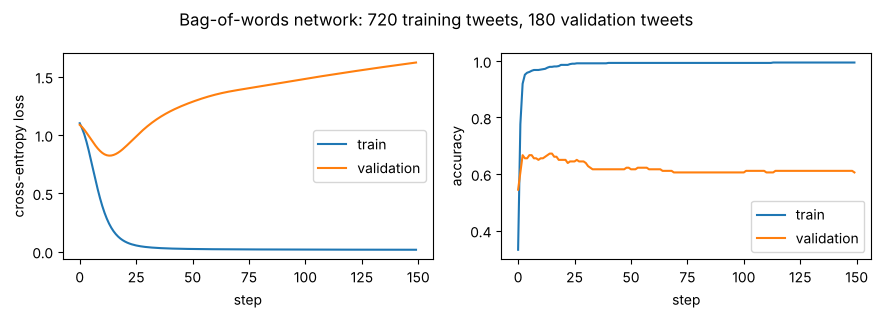

Lowest validation loss after 14 steps: loss 0.822, accuracy 0.667
After all 150 steps: train accuracy 0.994, validation accuracy 0.606


In [30]:
LR = 0.01
MAX_STEPS = 150

torch.manual_seed(0)
explore_net = make_network(X_sub.shape[1])
history = train_network(explore_net, X_sub, y_sub, X_val, y_val, lr=LR, epochs=MAX_STEPS)
plot_history(history, "Bag-of-words network: 720 training tweets, 180 validation tweets")

best_steps = int(np.argmin(history["val_loss"])) + 1
print(f"Lowest validation loss after {best_steps} steps: "
      f"loss {history['val_loss'][best_steps - 1]:.3f}, accuracy {history['val_acc'][best_steps - 1]:.3f}")
print(f"After all {MAX_STEPS} steps: train accuracy {history['train_acc'][-1]:.3f}, "
      f"validation accuracy {history['val_acc'][-1]:.3f}")

The training loss keeps going down, but the validation loss stops improving and then goes up: the network starts memorising the 720 training tweets. `best_steps` is used for the final network below.

#### Experiments from the Lecture

**Learning rate.** The lecture's table used plain gradient descent, $w \leftarrow w - \text{lr} \times \text{gradient}$: a learning rate that is too small crawls toward the minimum, and one that is too big bounces around or blows up. `torch.optim.SGD` does the same update, so the same thing happens here (720 sub-training tweets).

Adam, used for the main training, adjusts the step size of each weight as it goes, so it is less sensitive to the learning rate. That is why `lr = 0.01` works for it.

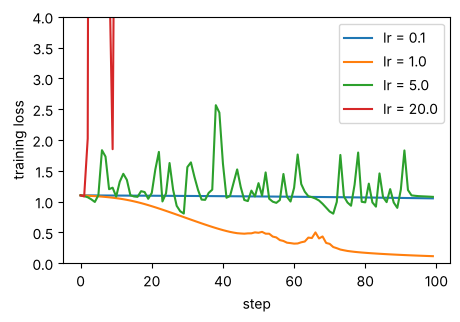

In [31]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for lr in (0.1, 1.0, 5.0, 20.0):  # Try 0.01 for an even slower crawl
    torch.manual_seed(0)
    lr_history = train_network(make_network(X_sub.shape[1]), X_sub, y_sub, lr=lr, epochs=100,
                               optimizer=torch.optim.SGD)
    ax.plot(lr_history["train_loss"], label=f"lr = {lr}")
ax.set_xlabel("step")
ax.set_ylabel("training loss")
ax.set_ylim(0, 4)
ax.legend()
plt.show()

**Activation function and hidden layer size.** Try sigmoid, tanh and ReLU (the lecture's activation plots) and a few hidden sizes. Each is scored on the validation set, at its best step.

In [32]:
rows = []
for activation in (torch.nn.Sigmoid, torch.nn.Tanh, torch.nn.ReLU):
    for hidden_size in (1, 8, 32, 128):  # 1 hidden neuron has to squeeze every tweet into a single number
        torch.manual_seed(0)
        h = train_network(make_network(X_sub.shape[1], hidden_size, activation), X_sub, y_sub, X_val, y_val,
                          lr=LR, epochs=MAX_STEPS)
        best = int(np.argmin(h["val_loss"]))
        rows.append({"activation": activation.__name__, "hidden size": hidden_size, "best step": best + 1,
                     "validation loss": round(h["val_loss"][best], 3), "validation accuracy": round(h["val_acc"][best], 3)})

pd.DataFrame(rows).pivot(index="activation", columns="hidden size", values="validation accuracy")

hidden size,1,8,32,128
activation,,,,
ReLU,0.461,0.633,0.667,0.661
Sigmoid,0.528,0.611,0.594,0.622
Tanh,0.533,0.606,0.622,0.611


- ReLU with 32 hidden neurons, the setting used for the final network below, is at or near the top, so the table backs up that choice.
- With 1 hidden neuron every activation does badly. Like the 1-neuron XOR network in the lecture, one number per tweet is not enough to separate three labels.
- With 180 validation tweets, one tweet is 0.6 percentage points, so small differences in this table can be luck.

#### Final Network

Retrain on all 900 training tweets for `best_steps` steps, with the settings from above (ReLU, 32 hidden neurons, Adam with `lr = 0.01`), and evaluate on the test set once.

Neural network test accuracy: 0.6333  (38 of 60 correct)

              precision    recall  f1-score   support

    negative      0.714     0.750     0.732        20
     neutral      0.500     0.650     0.565        20
    positive      0.769     0.500     0.606        20

    accuracy                          0.633        60
   macro avg      0.661     0.633     0.634        60
weighted avg      0.661     0.633     0.634        60



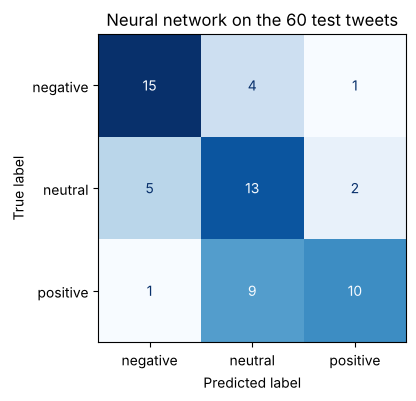

In [33]:
# Final network: vocabulary and weights from all 900 training tweets
final_vectorizer = CountVectorizer(binary=False)
X_train = to_tensor(final_vectorizer.fit_transform(train_text))
X_test = to_tensor(final_vectorizer.transform(test_text))
y_train = torch.tensor(y_train_all)

torch.manual_seed(0)
bow_net = make_network(X_train.shape[1])
train_network(bow_net, X_train, y_train, lr=LR, epochs=best_steps)

with torch.no_grad():
    test_scores = bow_net(X_test)
nn_proba = torch.softmax(test_scores, dim=1)   # Turn the 3 scores into probabilities that add up to 1
nn_predictions = [CLASSES[i] for i in test_scores.argmax(dim=1).tolist()]

nn_correct = sum(t == p for t, p in zip(test_labels, nn_predictions))
print(f"Neural network test accuracy: {accuracy_score(test_labels, nn_predictions):.4f}  "
      f"({nn_correct} of {len(test_labels)} correct)\n")
print(classification_report(test_labels, nn_predictions, digits=3))

cm = confusion_matrix(test_labels, nn_predictions, labels=CLASSES)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Neural network on the 60 test tweets")
plt.show()

That accuracy comes from one set of random starting weights (`torch.manual_seed(0)`). Retrain with a few other seeds to see how much it depends on them:

In [34]:
# Same data and settings, different random starting weights
nn_seed_accs = []
for seed in range(5):
    torch.manual_seed(seed)
    seed_net = make_network(X_train.shape[1])
    train_network(seed_net, X_train, y_train, lr=LR, epochs=best_steps)
    with torch.no_grad():
        nn_seed_accs.append(accuracy(seed_net(X_test), y_test))
print(f"Test accuracy with seeds 0-4: {np.round(nn_seed_accs, 3)}, "
      f"mean {np.mean(nn_seed_accs):.3f} ± {np.std(nn_seed_accs):.3f}")

Test accuracy with seeds 0-4: [0.633 0.567 0.583 0.5   0.617], mean 0.580 ± 0.046


In [35]:
# Softmax probabilities for the first 5 test tweets, next to Naive Bayes
pd.DataFrame(nn_proba[:5].numpy().round(3), columns=CLASSES).assign(
    nn=nn_predictions[:5], naive_bayes=sklearn_predictions[:5], true=test_labels[:5], tweet=test_df["text"][:5])

,negative,neutral,positive,nn,naive_bayes,true,tweet
0,0.426,0.228,0.346,negative,negative,negative,"@JetBlue before departure, while people who are delayed get up to $200 to compensate their time.."
1,0.364,0.353,0.283,negative,neutral,negative,"@united yes please! I am newly married and trying to update my last name on a preexisting international flight! It seems so easy, but..."
2,0.720,0.074,0.206,negative,negative,negative,"@USAirways @AmericanAir did I mention I'm a silver preferred member and fly every week (not always with you), and not even a meal voucher?"
3,0.622,0.158,0.220,negative,negative,negative,@united Are your earnings so low that checkin people have to also be on Tarmac loading bags? JAN
4,0.964,0.019,0.017,negative,negative,negative,"@USAirways your customer service is a joke. First a mechanical Cancelled Flightation, now weather. On hold since 5:30 am. No humans. Pls..."


### 11. Learned 2-D Word Embeddings

The lecture plotted four hand-made 2-D word vectors (`sleep`, `tired`, `study`, `coffee`). Here the network **learns** a 2-D vector for every word from the labels:

- `torch.nn.EmbeddingBag(..., mode="mean")` looks up the 2-D vector of each word in a tweet and averages them
- `Linear(2, 3)` turns that average into one score per label

Because each word only has 2 numbers, we can plot every word directly. Words that push toward the same label should end up close together.

Most words appear in only one or two tweets, and the network can give those words extreme vectors that fit the training tweets perfectly. `weight_decay` in the optimizer adds a small penalty for large weights, which keeps the vectors of rare words near 0 unless the data really pushes them out.

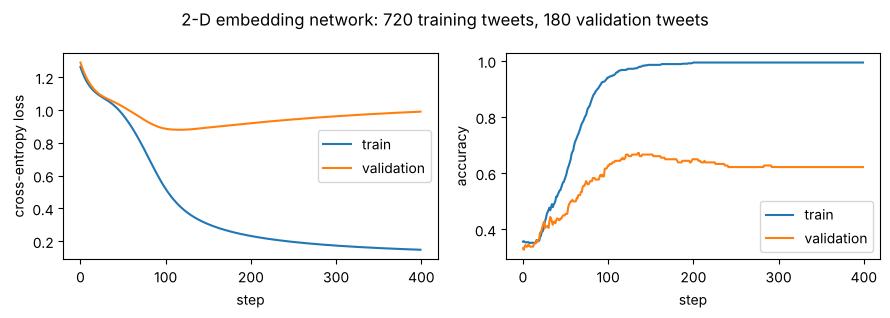

Lowest validation loss after 117 steps, validation accuracy 0.650


In [36]:
def to_word_ids(texts, vectorizer):
    # Each tweet -> the vocabulary index of each of its words, padded with PAD to the same length
    analyzer = vectorizer.build_analyzer()
    pad = len(vectorizer.vocabulary_)
    ids = [[vectorizer.vocabulary_[w] for w in analyzer(text) if w in vectorizer.vocabulary_] for text in texts]
    longest = max(len(i) for i in ids)
    return torch.tensor([i + [pad] * (longest - len(i)) for i in ids])


def make_embedding_network(vocab_size, embedding_size=2):
    return torch.nn.Sequential(
        # One extra row for PAD, padding_idx leaves it out of the average
        torch.nn.EmbeddingBag(vocab_size + 1, embedding_size, mode="mean", padding_idx=vocab_size),
        torch.nn.Linear(embedding_size, len(CLASSES)),
    )


# Pick the number of steps on the validation set, same as before
ids_sub = to_word_ids(sub_text, nn_vectorizer)
ids_val = to_word_ids(val_text, nn_vectorizer)

EMB_LR = 0.02
EMB_WEIGHT_DECAY = 0.001
torch.manual_seed(0)
embedding_history = train_network(make_embedding_network(len(nn_vectorizer.vocabulary_)), ids_sub, y_sub,
                                  ids_val, y_val, lr=EMB_LR, epochs=400, weight_decay=EMB_WEIGHT_DECAY)
plot_history(embedding_history, "2-D embedding network: 720 training tweets, 180 validation tweets")
best_embedding_steps = int(np.argmin(embedding_history["val_loss"])) + 1
print(f"Lowest validation loss after {best_embedding_steps} steps, "
      f"validation accuracy {embedding_history['val_acc'][best_embedding_steps - 1]:.3f}")

In [37]:
# Retrain on all 900 training tweets (same vocabulary as the final bag-of-words network)
ids_train = to_word_ids(train_text, final_vectorizer)
ids_test = to_word_ids(test_text, final_vectorizer)

torch.manual_seed(0)
embedding_net = make_embedding_network(len(final_vectorizer.vocabulary_))
train_network(embedding_net, ids_train, y_train, lr=EMB_LR, epochs=best_embedding_steps, weight_decay=EMB_WEIGHT_DECAY)

with torch.no_grad():
    embedding_scores = embedding_net(ids_test)
embedding_predictions = [CLASSES[i] for i in embedding_scores.argmax(dim=1).tolist()]
print(f"2-D embedding network test accuracy: {accuracy_score(test_labels, embedding_predictions):.4f}")

# Same check as before: how much does the test accuracy depend on the random starting weights?
emb_seed_accs = []
for seed in range(5):
    torch.manual_seed(seed)
    seed_net = make_embedding_network(len(final_vectorizer.vocabulary_))
    train_network(seed_net, ids_train, y_train, lr=EMB_LR, epochs=best_embedding_steps, weight_decay=EMB_WEIGHT_DECAY)
    with torch.no_grad():
        emb_seed_accs.append(accuracy(seed_net(ids_test), y_test))
print(f"Test accuracy with seeds 0-4: {np.round(emb_seed_accs, 3)}, "
      f"mean {np.mean(emb_seed_accs):.3f} ± {np.std(emb_seed_accs):.3f}")

2-D embedding network test accuracy: 0.6667


Test accuracy with seeds 0-4: [0.667 0.65  0.6   0.633 0.6  ], mean 0.630 ± 0.027


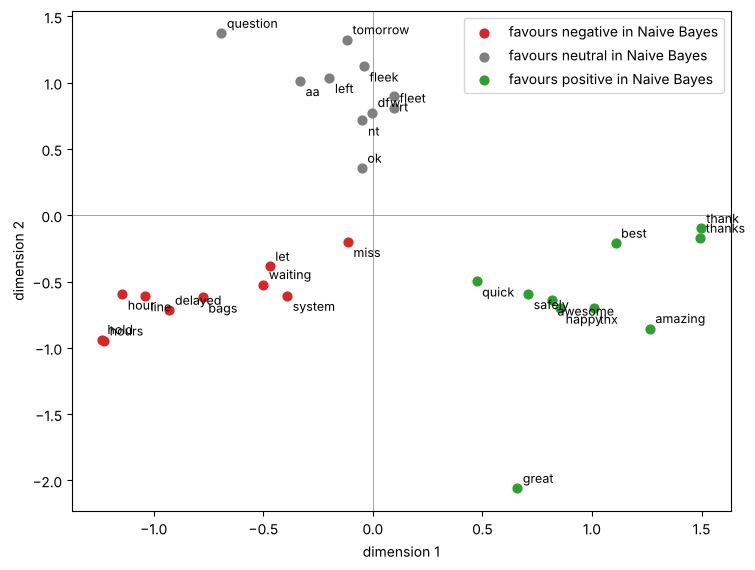

In [38]:
# The learned 2-D vector of every word (drop the PAD row)
emb = embedding_net[0].weight.detach()[:-1]
final_vocab = final_vectorizer.vocabulary_
final_counts = np.asarray(final_vectorizer.transform(train_text).sum(axis=0)).ravel()

# Plot the words that favour each label most in Naive Bayes (section 8) and appear at least 5 times
colors = {"negative": "tab:red", "neutral": "tab:gray", "positive": "tab:green"}
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for c in CLASSES:
    ranked = [sk_vocab[j] for j in class_margin[c].argsort()[::-1]]
    words = [w for w in ranked if final_counts[final_vocab[w]] >= 5][:10]
    points = emb[[final_vocab[w] for w in words]]
    ax.scatter(points[:, 0], points[:, 1], s=40, color=colors[c], label=f"favours {c} in Naive Bayes")
    for k, (w, (x, y)) in enumerate(zip(words, points.tolist())):
        # Alternate the label above and below the point so close words do not overlap as much
        ax.annotate(w, (x, y), xytext=(4, 4 if k % 2 == 0 else -11), textcoords="offset points", fontsize=9)
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel("dimension 1")
ax.set_ylabel("dimension 2")
ax.legend()
plt.show()

In [39]:
# Distance to a word, like the lecture's distance to "sleep" (only words that appear at least 5 times)
frequent = [w for w, j in final_vocab.items() if final_counts[j] >= 5]

for anchor in ["thanks", "delayed", "question"]:
    dist = ((emb - emb[final_vocab[anchor]]) ** 2).sum(dim=1).sqrt()
    ranked = sorted((w for w in frequent if w != anchor), key=lambda w: dist[final_vocab[w]].item())
    print(f"Closest to {anchor!r}:  " + ", ".join(f"{w} {dist[final_vocab[w]]:.2f}" for w in ranked[:8]))
    print(f"Farthest from {anchor!r}: " + ", ".join(f"{w} {dist[final_vocab[w]]:.2f}" for w in ranked[::-1][:8]) + "\n")

Closest to 'thanks':  thank 0.07, best 0.39, guys 0.61, den 0.63, thx 0.72, amazing 0.72, attendant 0.72, trip 0.75
Farthest from 'thanks': hold 2.84, hours 2.83, question 2.68, hour 2.67, voucher 2.63, line 2.57, delayed 2.48, need 2.46

Closest to 'delayed':  cancelled 0.14, line 0.16, bags 0.18, help 0.18, hour 0.25, customer 0.25, service 0.34, late 0.35
Farthest from 'delayed': thank 2.50, thanks 2.48, flying 2.29, amazing 2.20, tomorrow 2.20, good 2.19, question 2.10, best 2.10

Closest to 'question':  aa 0.51, tomorrow 0.58, left 0.60, email 0.60, fleek 0.70, reservation 0.74, passengers 0.75, flights 0.76
Farthest from 'question': great 3.69, amazing 2.96, united 2.94, agent 2.72, helpful 2.69, thx 2.68, thanks 2.68, thank 2.64



Like `sleep` / `tired` and `study` / `coffee` in the lecture, words that push toward the same label end up close together. The difference is that nobody chose these vectors: the network only saw the tweets and their labels, and moved each word's vector to make the labels easier to predict.

### 12. Summary

In [40]:
# Naive Bayes has no random starting weights, so every seed gives the same accuracy
nb_accuracy = accuracy_score(test_labels, sklearn_predictions)
summary = pd.DataFrame([
    {"model": "Naive Bayes from scratch", "test accuracy (seed 0)": accuracy_score(test_labels, scratch_predictions),
     "mean over seeds 0-4": accuracy_score(test_labels, scratch_predictions)},
    {"model": "Naive Bayes (scikit-learn)", "test accuracy (seed 0)": nb_accuracy, "mean over seeds 0-4": nb_accuracy},
    {"model": "Neural network on bag of words", "test accuracy (seed 0)": accuracy_score(test_labels, nn_predictions),
     "mean over seeds 0-4": np.mean(nn_seed_accs)},
    {"model": "2-D word embedding network", "test accuracy (seed 0)": accuracy_score(test_labels, embedding_predictions),
     "mean over seeds 0-4": np.mean(emb_seed_accs)},
])
summary["test correct (seed 0, of 60)"] = (summary["test accuracy (seed 0)"] * len(test_labels)).round().astype(int)
summary.round(3)

,model,test accuracy (seed 0),mean over seeds 0-4,"test correct (seed 0, of 60)"
0,Naive Bayes from scratch,0.600,0.60,36
1,Naive Bayes (scikit-learn),0.600,0.60,36
2,Neural network on bag of words,0.633,0.58,38
3,2-D word embedding network,0.667,0.63,40


- With 60 test tweets, each tweet is 1.7 percentage points, so a gap of a few tweets between models can be luck.
- The networks also depend on their random starting weights: compare the seed 0 column with the mean over 5 seeds.
- On this test set, neither network is clearly better than Naive Bayes, which is simpler and gives the same answer every run.
- The models do make different mistakes: compare the confusion matrices in sections 7 and 10.
- Cross-validation (section 9) is a steadier way to compare choices than the 60 test tweets.

### 13. Try Your Own Tweets

Any new tweet has to go through the same pre-processing as the training data before it reaches the model.

In [41]:
def predict_sentiment(tweets):
    cleaned = [spacy_preprocess(regex_clean(t)) for t in tweets]
    nb_labels = model.predict(cleaned)
    with torch.no_grad():
        nn_probabilities = torch.softmax(bow_net(to_tensor(final_vectorizer.transform(cleaned))), dim=1)
    for tweet, clean, nb_label, p in zip(tweets, cleaned, nb_labels, nn_probabilities):
        print(f"Tweet:          {tweet}")
        print(f"Cleaned:        {clean}")
        print(f"Naive Bayes:    {nb_label}")
        print(f"Neural network: {CLASSES[int(p.argmax())]}  "
              + "  ".join(f"P({c}) = {p[i]:.2f}" for i, c in enumerate(CLASSES)) + "\n")


predict_sentiment([
    "@united thank you for the quick rebooking, the crew was great!",
    "@AmericanAir my bag is lost and nobody answers the phone",
    "@JetBlue what time does boarding start for flight 123 tomorrow?",
    "@SouthwestAir not happy at all, delayed again",
])

Tweet:          @united thank you for the quick rebooking, the crew was great!
Cleaned:        thank quick rebooking crew great
Naive Bayes:    positive
Neural network: positive  P(negative) = 0.07  P(neutral) = 0.09  P(positive) = 0.85

Tweet:          @AmericanAir my bag is lost and nobody answers the phone
Cleaned:        bag lost answers phone
Naive Bayes:    negative
Neural network: negative  P(negative) = 0.83  P(neutral) = 0.08  P(positive) = 0.09

Tweet:          @JetBlue what time does boarding start for flight 123 tomorrow?
Cleaned:        time boarding start flight 123 tomorrow
Naive Bayes:    neutral
Neural network: neutral  P(negative) = 0.06  P(neutral) = 0.79  P(positive) = 0.15

Tweet:          @SouthwestAir not happy at all, delayed again
Cleaned:        happy delayed
Naive Bayes:    negative
Neural network: positive  P(negative) = 0.38  P(neutral) = 0.19  P(positive) = 0.43



Look at the cleaned text of the last tweet: `not`, `at`, `all` and `again` are spaCy stopwords, so the models only see "happy delayed".

Keeping the `not` only when predicting would not help. `model` and `bow_net` were trained on version C, so `not` is not in their vocabulary and `CountVectorizer` would drop it. The version D model from section 9 was trained with the negations kept:

In [42]:
# Version D keeps the negations, both in training and here
d_model = version_models["D. C + keep negations"]
tweet = "@SouthwestAir not happy at all, delayed again"
d_clean = spacy_preprocess(regex_clean(tweet), keep_negations=True)
d_proba = d_model.predict_proba([d_clean])[0]

print(f"Cleaned (version D):     {d_clean}")
print(f"Naive Bayes (version D): {d_model.predict([d_clean])[0]}  "
      + "  ".join(f"P({c}) = {p:.2f}" for c, p in zip(d_model.classes_, d_proba)))

Cleaned (version D):     not happy delayed
Naive Bayes (version D): negative  P(negative) = 0.81  P(neutral) = 0.05  P(positive) = 0.14


### Ideas to Try

- `CountVectorizer(binary = True)`: only record whether a word appears, not how often
- `CountVectorizer(ngram_range = (1, 2))`: add word pairs like "customer service" as features (with `keep_negations = True`, also "not happy")
- Keep emoji: `CountVectorizer(token_pattern = r"(?u)\b\w\w+\b|[^\w\s]")` also keeps single symbols like 🙏 and 😭
- Use `token.lemma_` instead of `token.text` in `spacy_preprocess`, so "delayed" and "delays" become one word
- Change `MultinomialNB(alpha = 1)` to a smaller or bigger smoothing value and compare the cross-validation accuracy